In [1]:
import numpy as np
import pymc as pm  # if using pymc >=4
import arviz as az
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns

import pandas as pd
import os

import json

from pytensor.tensor import cumsum
import pytensor.tensor as at

from glob import glob

import mvEEG.mvEEG as mvEEG

In [2]:
OVERWRITE_MODELS = True
DESCRIPTION = "signedDprime"  # description for saving outputs, either "signedDprime" or "signedCorrWhite"
if DESCRIPTION == "signedCorrWhite":
    RESCALE = 1e6  # rescaling factor for RDMs to improve numerical stability in Bayesian models
else:
    RESCALE = 1  # if not rescaling, then set to 1 (i.e., no rescaling)

In [3]:
conditions = [
    "A2N",
    "A4N",
    "A6N",
    "A8N",
    "A2P",
    "A4P",
    "A6P",
    "A8P",
    "M2N",
    "M4N",
    "M6N",
    "M8N",
    "M2P",
    "M4P",
    "M6P",
    "M8P",
]

ridx, cidx = np.triu_indices(len(conditions), k=1)

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan"

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans={},
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1000],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 900
)  # time window to average distances over, only includes when probes could appear

In [4]:
with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['006', '008', '017', '018', '020', '023', '024', '016']

In [5]:
# df["median_split"] = (df.response<df.response.quantile()).replace({True:1, False:2})
f = open("k_estimates.json")
k_res = json.load(f)
k_df = pd.DataFrame(pd.DataFrame(k_res).loc[["4", "6", "8"]].mean())  # average across SS4-8
k_df = k_df[~k_df.index.isin(rejected_subs)]  # remove rejected subjects
k_df["high_k"] = k_df[0] > k_df[0].quantile()
k_df["contrast"] = k_df.index.map(lambda sub: 0.5 if k_df.loc[sub, "high_k"] else -0.5)

sub_contrast_vec = k_df["contrast"].values
sub_group_vec = k_df["high_k"].astype(int).values

k_df

,0,high_k,contrast
001,4.523043,True,0.5
002,0.467553,False,-0.5
003,4.563474,True,0.5
004,3.815850,True,0.5
005,1.962259,False,-0.5
007,2.591679,False,-0.5
009,4.119600,True,0.5
010,3.952438,True,0.5
011,3.974817,True,0.5
012,1.683720,False,-0.5


In [6]:
sub_contrast_vec, sub_group_vec

(array([ 0.5, -0.5,  0.5,  0.5, -0.5, -0.5,  0.5,  0.5,  0.5, -0.5,  0.5,
        -0.5,  0.5, -0.5, -0.5,  0.5, -0.5,  0.5, -0.5,  0.5, -0.5, -0.5,
        -0.5,  0.5,  0.5, -0.5]),
 array([1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0,
        0, 1, 1, 0]))

In [7]:
len(sub_contrast_vec)

26

In [8]:
rdm_files = sorted(glob(f"../data/derivatives/*/RDMs/*desc-{DESCRIPTION}*npy"))
rdm_files = [f for f in rdm_files if f.split("-")[1].split("/")[0] not in rejected_subs]
rdm_files

['../data/derivatives/sub-001/RDMs/sub-001_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-002/RDMs/sub-002_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-003/RDMs/sub-003_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-004/RDMs/sub-004_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-005/RDMs/sub-005_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-007/RDMs/sub-007_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-009/RDMs/sub-009_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-010/RDMs/sub-010_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-011/RDMs/sub-011_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-012/RDMs/sub-012_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-013/RDMs/sub-013_task-banyan_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-014/RDMs/sub-014_task-banyan_desc-signedDprime_rdm.npy',
 '..

In [9]:
len(rdm_files)

26

In [10]:
# Number of Items in WM
WM_setsizes = np.array([int(cond[1]) if (cond[0] == "M") else 0 for cond in conditions])
WMss_options = sorted(np.unique(WM_setsizes))
WM_setsize_map = {ss: i for i, ss in enumerate(WMss_options)}
cond_WMss_idx = np.array([WM_setsize_map[ss] for ss in WM_setsizes])

# Number of attended areas, assuming that people can filter our distractors
condition_ATTN = np.array([int(cond[1]) for cond in conditions])
ATTNss_options = sorted(np.unique(condition_ATTN))
ATTN_setsize_map = {ss: i for i, ss in enumerate(ATTNss_options)}
cond_ATTNss_idx = np.array([ATTN_setsize_map[ss] for ss in condition_ATTN])

# stimulus energy, carved up for a monotonic function
condition_stimEnergy = np.array([int(cond[1]) if cond[2] == "N" else 10 for cond in conditions])
stimEnergy_options = sorted(np.unique(condition_stimEnergy))
stimEnergy_map = {ss: i for i, ss in enumerate(stimEnergy_options)}
cond_stimEnergy_idx = np.array([stimEnergy_map[ss] for ss in condition_stimEnergy])

q = np.array(
    [
        cond_WMss_idx[ridx],
        cond_WMss_idx[cidx],
        cond_ATTNss_idx[ridx],
        cond_ATTNss_idx[cidx],
        cond_stimEnergy_idx[ridx],
        cond_stimEnergy_idx[cidx],
    ]
).T

<Axes: >

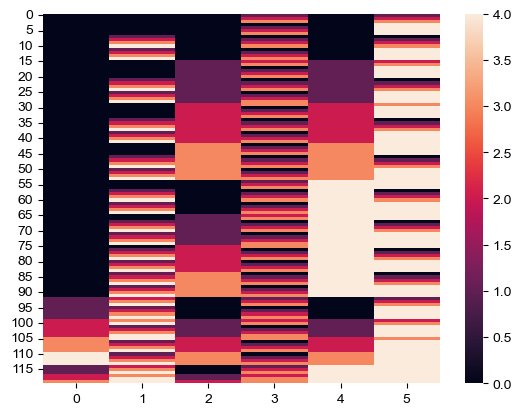

In [11]:
sns.heatmap(q)

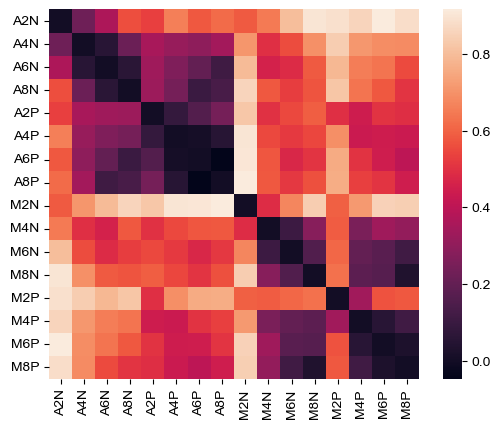

In [12]:
group_rdm = np.zeros((len(conditions), len(conditions)))
for i, f in enumerate(rdm_files):
    sub_id = f.split("-")[1].split("/")[0]
    sub_rdms = np.load(f)
    sub_rdm_delay = sub_rdms[..., delay_window].mean(-1)
    group_rdm += sub_rdm_delay
group_rdm /= len(rdm_files)
_ = sns.heatmap(group_rdm, xticklabels=conditions, yticklabels=conditions, square=True)
plt.savefig(f"figures/group_rdm_{DESCRIPTION}.png", transparent=True, bbox_inches="tight")

# CURRENT MODEL

In [13]:
def build_model(d, q):
    """
    Build a model to estimate the WM and spatial attention functions with the following assumptions:
    1. The WM function is a guassian random walk, **is the same with or without placeholders**
    2. The spatial attention function is monotonic, **and is the same with or without placeholders**
    3. The stimulus energy function is monotonic

    **s indicate assumptions specific to this model

    Arguments
    ---------
    d : array of shape (n_distances,)
        The vectorized distances in upper (or lower) triangle of RDM
    q : array of shape (n_distances, n_regressors)
        Condition indices
    For this model the following column structure is expected:
    0. WM set size at first condition
    1. WM set size at second condition
    2. Spatial attention set size at first condition
    3. Spatial attention set size at second condition
    4. Stimulus energy at first condition
    5. Stimulus energy at second condition
    6. unique subject index for each distance (i.e., same for all distances from the same subject)

    """
    N = len(d)
    wmK = np.unique(q[:, :2]).size  # number of WM set sizes
    attnK = np.unique(q[:, 2:4]).size  # number of attended areas
    StimEnergyK = np.unique(q[:, 4:6]).size  # number of stimulus energy levels
    nsub = np.unique(q[:, 6]).size  # number of subjects

    # check that the quad indices are in the expected format
    assert np.min(q) == 0
    assert q.shape[0] == N
    assert (np.max(q[:, :2]) + 1) == wmK
    assert (np.max(q[:, 2:4]) + 1) == attnK
    assert (np.max(q[:, 4:6]) + 1) == StimEnergyK

    # steps between conditions we'd like to fit to data
    coords = {
        "innovations_num_WM": np.arange(1, wmK),
        "innovations_num_Attn": np.arange(1, attnK),
        "innovations_num_SE": np.arange(1, StimEnergyK),
        "subject": np.arange(0, nsub),
        "trial_num": np.arange(1, N + 1),
    }

    with pm.Model(coords=coords) as model:

        # prior on noise in RDM values, used in likelihood below
        RDM_sigma_pop = pm.Exponential("RDM_sigma_pop", lam=5)  # OLD lam=10
        RDM_sigma_subs = pm.Exponential("RDM_sigma_subs", lam=1 / RDM_sigma_pop, dims=("subject",))

        # ~~~~~~~~~~~~ 1. Working Memory ~~~~~~~~~~~~

        # WM prior on changes between successive levels in underlying function
        # assumes gaussian process, with random step between levels
        # population-level walk
        scale_innov_WM = pm.Exponential("scale_innov_WM", lam=1)  # scale of innovations before exp transform

        # group-level function
        log_mu_WM = pm.GaussianRandomWalk(
            "log_mu_WM_minus_first",
            mu=0,
            sigma=1,
            init_dist=pm.Normal.dist(0, 1),
            dims=("innovations_num_WM",),
        )
        mu_WM = pm.Deterministic("mu_WM", pm.math.exp(scale_innov_WM * log_mu_WM))  # convert to positives, scale

        sigma_lvls_prior_WM = pm.Exponential(
            "sigma_lvls_hyperprior_WM", lam=4
        )  # prior on variability of the subjects at each set size - setting it broad to include very small values
        sigma_lvls_WM = pm.Exponential("sigma_lvls_WM", scale=sigma_lvls_prior_WM, dims=("innovations_num_WM",))

        sub_vals_WM = pm.TruncatedNormal(
            "sub_vals_WM_minus_first",
            mu=mu_WM,
            sigma=sigma_lvls_WM,
            lower=0,
            dims=("subject", "innovations_num_WM"),
        )
        sub_vals_WM = pm.Deterministic("sub_vals_WM", at.concatenate((np.zeros((nsub, 1)), sub_vals_WM), axis=1))

        # ~~~~~~~~~~~~ 2. Spatial Attention ~~~~~~~~~~~~
        # define the population-level dirichlet prior
        pop_dir_Attn = pm.Dirichlet("pop_dir_Attn", a=np.ones(attnK - 1), dims=("innovations_num_Attn",))
        pop_dir_scale_Attn = pm.Exponential(
            "pop_dir_scale_Attn", lam=5
        )  # scale of dirichlet concentration, higher = less variance
        pop_concentration_Attn = pop_dir_scale_Attn * pop_dir_Attn

        # each subject's dirichlet is drawn from a scaled version of the population dirichlet
        sub_dir_Attn = pm.Dirichlet(
            "sub_dir_Attn",
            a=pop_concentration_Attn,
            dims=("subject", "innovations_num_Attn"),
        )
        sub_mu_Attn = pm.Deterministic("sub_mu_Attn_minus_first", cumsum(sub_dir_Attn, axis=1))
        sub_mu_Attn = pm.Deterministic("sub_mu_Attn", at.concatenate((np.zeros((nsub, 1)), sub_mu_Attn), axis=1))

        # subject scale is also hierarchical
        pop_scale_Attn = pm.Exponential("pop_scale_Attn", lam=5)
        sub_scale_Attn = pm.Exponential("sub_scale_Attn", lam=1 / pop_scale_Attn, dims=("subject",))

        # save the population function as a deterministic variable for later examination
        pop_mu_Attn = pm.Deterministic("pop_mu_Attn", pop_scale_Attn * cumsum(pop_dir_Attn, axis=0))

        # ~~~~~~~~~~~~ 3. Stimulus Energy ~~~~~~~~~~~~
        # define the population-level dirichlet prior
        pop_dir_SE = pm.Dirichlet("pop_dir_SE", a=np.ones(StimEnergyK - 1), dims=("innovations_num_SE",))
        pop_dir_scale_SE = pm.Exponential("pop_dir_scale_SE", lam=5)
        pop_concentration_SE = pop_dir_scale_SE * pop_dir_SE

        # each subject's dirichlet is drawn from a scaled version of the population dirichlet
        sub_dir_SE = pm.Dirichlet(
            "sub_dir_SE",
            a=pop_concentration_SE,
            dims=("subject", "innovations_num_SE"),
        )
        sub_mu_SE = pm.Deterministic("sub_mu_SE_minus_first", cumsum(sub_dir_SE, axis=1))
        sub_mu_SE = pm.Deterministic("sub_mu_SE", at.concatenate((np.zeros((nsub, 1)), sub_mu_SE), axis=1))

        # subject scale is also hierarchical
        pop_scale_SE = pm.Exponential("pop_scale_SE", lam=5)
        sub_scale_SE = pm.Exponential("sub_scale_SE", lam=1 / pop_scale_SE, dims=("subject",))

        # save the population function as a deterministic variable for later examination
        pop_mu_SE = pm.Deterministic("pop_mu_SE", pop_scale_SE * cumsum(pop_dir_SE, axis=0))

        # ~~~~~~~~~~~~ 4. Combine into full model ~~~~~~~~~~~~

        # start by getting difference scores between pairs of conds based on WM, Attn, and StimEnergy levels
        # WM
        mu_i_WM = sub_vals_WM[q[:, 6].astype(int), q[:, 0].astype(int)]
        mu_j_WM = sub_vals_WM[q[:, 6].astype(int), q[:, 1].astype(int)]
        mu_delta_WM = pm.math.abs(mu_i_WM - mu_j_WM)

        # NOTE: attn and stim energy are flipped axes (subject, levels) compared to WM
        # Attn
        mu_i_Attn = sub_mu_Attn[q[:, 6].astype(int), q[:, 2].astype(int)]
        mu_j_Attn = sub_mu_Attn[q[:, 6].astype(int), q[:, 3].astype(int)]
        mu_delta_Attn = pm.math.abs(mu_i_Attn - mu_j_Attn) * sub_scale_Attn[q[:, 6].astype(int)]

        # StimEnergy
        mu_i_SE = sub_mu_SE[q[:, 6].astype(int), q[:, 4].astype(int)]
        mu_j_SE = sub_mu_SE[q[:, 6].astype(int), q[:, 5].astype(int)]
        mu_delta_SE = pm.math.abs(mu_i_SE - mu_j_SE) * sub_scale_SE[q[:, 6].astype(int)]

        # likelihood function
        dist_est = mu_delta_WM + mu_delta_Attn + mu_delta_SE
        pm.Normal("d", mu=dist_est, sigma=RDM_sigma_subs[q[:, 6].astype(int)], observed=d, dims=("trial_num",))

    return model

In [14]:
# build up distances and inputs

for i, f in enumerate(rdm_files):
    sub_id = f.split("-")[1].split("/")[0]
    sub_rdms = np.load(f)
    sub_rdm_delay = sub_rdms[..., delay_window].mean(-1)

    sub_dists = sub_rdm_delay[ridx, cidx] * RESCALE  # vectorize upper triangle, rescale for numerical stability

    sub_q = np.concatenate(
        [
            q,
            # np.array([[k_df.loc[sub_id, "high_k"]] * q.shape[0]]).T,  # add column to differentiate k groups
            np.array([[i] * q.shape[0]]).T,  # add column to index subjects
        ],
        axis=1,
    )

    if i == 0:
        pop_dists = sub_dists
        pop_q = sub_q
    else:
        pop_dists = np.concatenate((pop_dists, sub_dists))
        pop_q = np.concatenate((pop_q, sub_q), axis=0)

print(pop_dists.shape, pop_q.shape)

(3120,) (3120, 7)


In [15]:
# fit model
# fit model
model_path = f"models/{DESCRIPTION}_model"
if (not os.path.exists(model_path)) or OVERWRITE_MODELS:
    model = build_model(pop_dists, pop_q)

    with model:
        trace = pm.sample(
            10_000,  # real samples per chain
            tune=10_000,  # warmup samples per chain
            chains=4,
            target_accept=0.9999,
            random_seed=2026,
            return_inferencedata=True,
            nuts_sampler="numpyro",
        )
        trace.to_netcdf(model_path)
else:
    trace = az.from_netcdf(model_path)

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

In [16]:
# check the effective sample size
summary_table = az.summary(trace)
summary_table

/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
log_mu_WM_minus_first[1],-1.534,0.592,-2.645,-0.508,0.005,0.004,12390.0,19660.0,1.0
log_mu_WM_minus_first[2],-2.148,0.826,-3.699,-0.705,0.008,0.005,11620.0,18552.0,1.0
log_mu_WM_minus_first[3],-2.165,0.862,-3.773,-0.680,0.008,0.006,11765.0,18098.0,1.0
log_mu_WM_minus_first[4],-2.141,0.875,-3.786,-0.658,0.008,0.006,11719.0,18832.0,1.0
RDM_sigma_pop,0.205,0.041,0.134,0.282,0.000,0.000,72002.0,27091.0,1.0
...,...,...,...,...,...,...,...,...,...
"sub_mu_SE[25, 4]",1.000,0.000,1.000,1.000,0.000,0.000,39088.0,39476.0,1.0
pop_mu_SE[0],0.142,0.034,0.082,0.205,0.000,0.000,42418.0,29752.0,1.0
pop_mu_SE[1],0.216,0.046,0.134,0.302,0.000,0.000,41564.0,28914.0,1.0
pop_mu_SE[2],0.278,0.056,0.178,0.383,0.000,0.000,55175.0,28996.0,1.0


In [17]:
summary_table.loc[summary_table.r_hat > 1.01]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [18]:
summary_table.r_hat.describe()

count    865.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: r_hat, dtype: float64

In [19]:
mini_summary = az.summary(trace, var_names=["mu_WM", "pop_dir_Attn", "pop_dir_scale_Attn"])
mini_summary.ess_bulk.describe()

count        8.000000
mean     21214.375000
std      17228.950461
min       2005.000000
25%       4830.500000
50%      23656.500000
75%      36841.500000
max      38173.000000
Name: ess_bulk, dtype: float64

2005.0


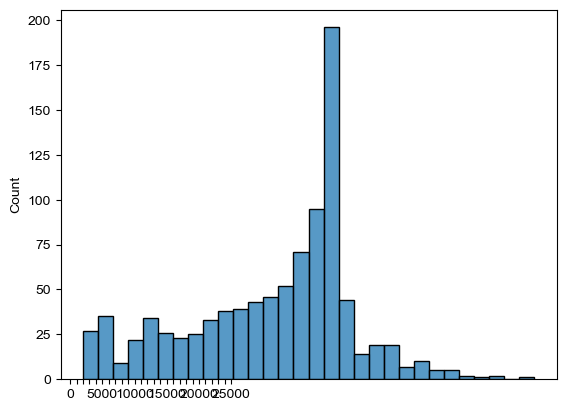

In [20]:
_ = sns.histplot(summary_table.ess_bulk.values, bins=30)
# only add xtick labels every 5000
_ = plt.xticks(range(0, 26000, 1000), labels=[str(x) if x % 5000 == 0 else "" for x in range(0, 26000, 1000)])

print(summary_table.ess_bulk.min())

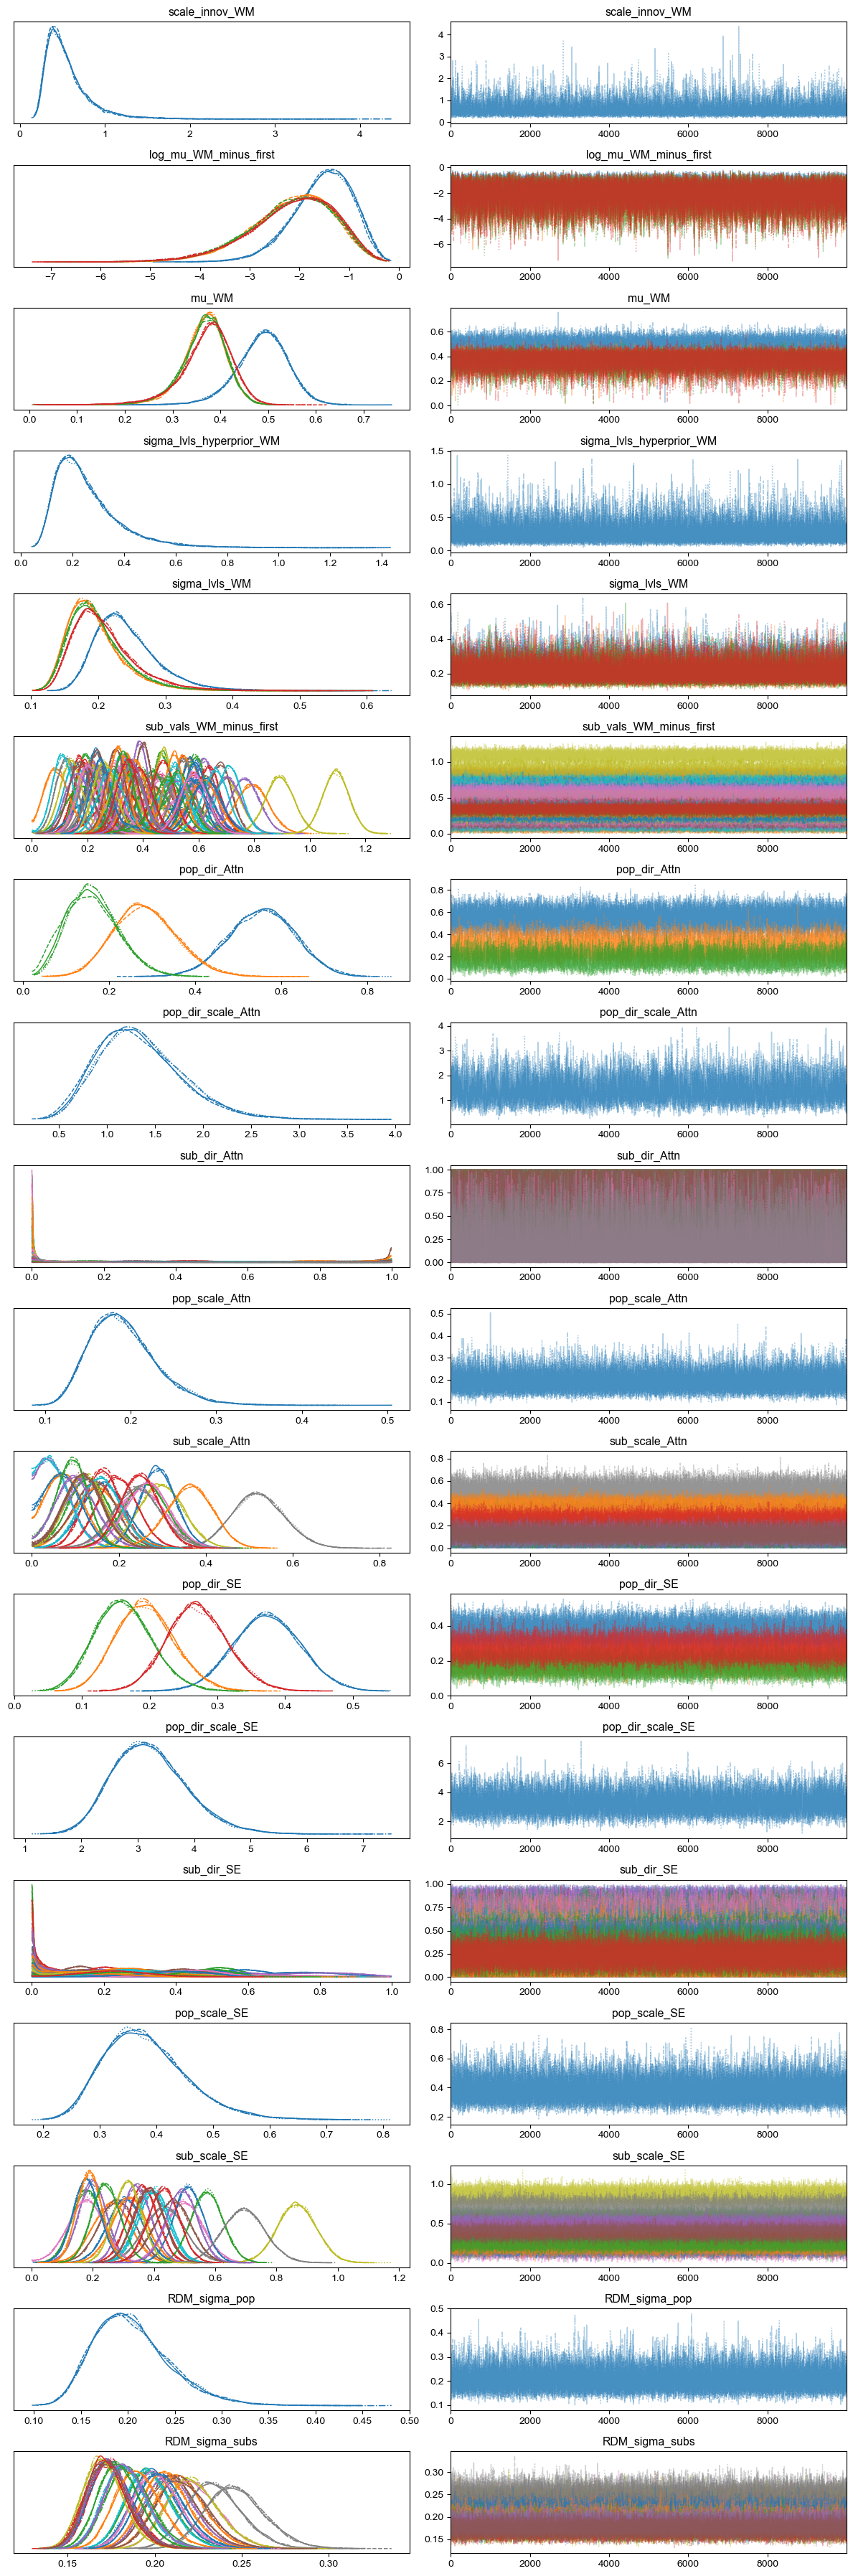

In [21]:
_ = pm.plot_trace(
    trace,
    var_names=[
        "scale_innov_WM",
        "log_mu_WM_minus_first",
        "mu_WM",
        "sigma_lvls_hyperprior_WM",
        "sigma_lvls_WM",
        "sub_vals_WM_minus_first",
        "pop_dir_Attn",
        "pop_dir_scale_Attn",
        "sub_dir_Attn",
        # "sub_mu_Attn_minus_first",
        "pop_scale_Attn",
        "sub_scale_Attn",
        "pop_dir_SE",
        "pop_dir_scale_SE",
        "sub_dir_SE",
        # "sub_mu_SE_minus_first",
        "pop_scale_SE",
        "sub_scale_SE",
        # "RDM_sigma",
        "RDM_sigma_pop",
        "RDM_sigma_subs",
    ],
)
plt.tight_layout()
plt.show()
plt.close()

# Pretty plots

In [22]:
hdi_prob = 0.94

trc = trace.posterior.stack(draws=("chain", "draw"))

param_xs = {"mu_WM": [0, 2, 4, 6, 8], "mu_Attn": [2, 4, 6, 8], "mu_SE": [2, 4, 6, 8, 10]}
condition_indices = {"mu_WM": cond_WMss_idx, "mu_Attn": cond_ATTNss_idx, "mu_SE": cond_stimEnergy_idx}


param_xlabels = {
    "mu_WM": "WM Set Size [0=Spatial Attention Task]",
    "mu_Attn": "# Attended Locations",
    "mu_SE": "# Stimuli in Display",
}

param_colors = {"mu_WM": "red", "mu_Attn": "blue", "mu_SE": "orange"}

param_titles = {
    "mu_WM": "Working Memory Load Function",
    "mu_Attn": "Spatial Attention Load Function",
    "mu_SE": "Stimulus Energy Load Function",
}

In [23]:
def plot_param(param, param_vals):
    # assumes param_vals is (n_param_levels, n_samples)
    lower = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 0]
    upper = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 1]

    ax = sns.lineplot(x=param_xs[param], y=param_vals.mean(1), color="dark" + param_colors[param], linewidth=2)
    plt.fill_between(param_xs[param], lower, upper, alpha=0.4, color="dark" + param_colors[param])

    plt.yticks(np.round(plt.yticks()[0], 1))

    plt.xticks(param_xs[param])
    plt.xlabel(param_xlabels[param])

    plt.ylabel("Neural Distance (d') from Baseline")
    plt.title(param_titles[param])
    sns.despine()
    plt.savefig(f"figures/{param}_pop.svg")
    plt.savefig(f"figures/{param}_pop.png", dpi=300)
    plt.show()
    plt.close()

    mean_vals = param_vals.mean(1)
    condition_vals = mean_vals[condition_indices[param]]
    sns.heatmap(
        np.abs(condition_vals[:, np.newaxis] - condition_vals[np.newaxis, :]),
        xticklabels=conditions,
        yticklabels=conditions,
        square=True,
    )
    plt.savefig(f"figures/expected_rdm_{param}.png", transparent=True, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_param_k_diffs(param, sub_vals):
    # assumes sub_vals is (n_subjects, n_param_levels, n_samples)

    # divide into subjects into groups and mean across subs within each group
    sub_vals_high_k = sub_vals[k_df.high_k.values, :, :].mean(0)
    sub_vals_low_k = sub_vals[~k_df.high_k.values, :, :].mean(0)
    sub_vals_diff = sub_vals_high_k - sub_vals_low_k

    high_K_hdi = az.hdi(sub_vals_high_k.T, hdi_prob=hdi_prob)
    low_k_hdi = az.hdi(sub_vals_low_k.T, hdi_prob=hdi_prob)
    diff_hdi = az.hdi(sub_vals_diff.T, hdi_prob=hdi_prob)

    ax = sns.lineplot(
        x=param_xs[param],
        y=sub_vals_high_k.mean(1),
        label="High K Subjects",
        color="dark" + param_colors[param],
        linewidth=2,
    )
    plt.fill_between(param_xs[param], high_K_hdi[:, 0], high_K_hdi[:, 1], alpha=0.4, color="dark" + param_colors[param])

    sns.lineplot(
        x=param_xs[param],
        y=sub_vals_low_k.mean(1),
        label="Low K Subjects",
        color=param_colors[param],
        ax=ax,
        linewidth=2,
    )
    plt.fill_between(param_xs[param], low_k_hdi[:, 0], low_k_hdi[:, 1], alpha=0.4, color=param_colors[param])

    sns.lineplot(x=param_xs[param], y=sub_vals_diff.mean(1), label="High K - Low K", color="black", ax=ax, linewidth=2)
    plt.fill_between(param_xs[param], diff_hdi[:, 0], diff_hdi[:, 1], alpha=0.4, color="black")

    plt.hlines(0, param_xs[param][0], param_xs[param][-1], linestyle="--", color="gray", zorder=-1)

    plt.xticks(param_xs[param])
    plt.xlabel(param_xlabels[param])
    plt.yticks(np.round(plt.yticks()[0], 1))
    plt.ylabel("Neural Distance (d') from Baseline")
    plt.legend(loc="upper left")
    plt.title(param_titles[param])
    sns.despine()
    plt.savefig(f"figures/{param}_split_half.svg")
    plt.savefig(f"figures/{param}_split_half.png", dpi=300)
    plt.show()
    plt.close()

# WM

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:3: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:4: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 1]


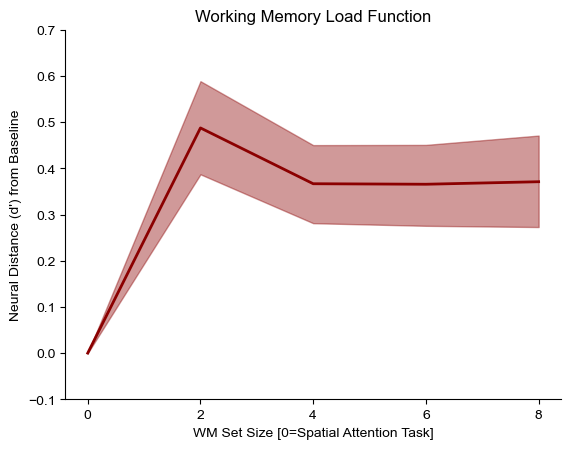

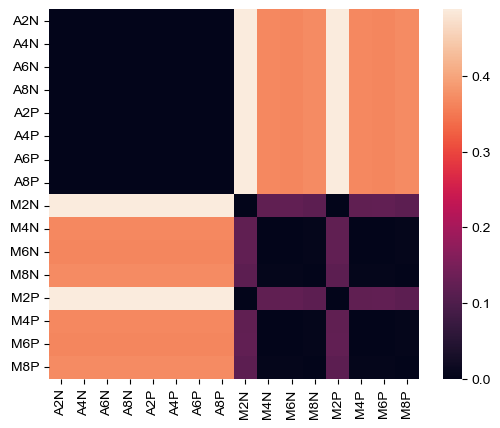

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:43: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  high_K_hdi = az.hdi(sub_vals_high_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:44: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  low_k_hdi = az.hdi(sub_vals_low_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:45: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  diff_hdi = az.hdi(sub_vals_diff.T, hdi_prob=hdi_prob)


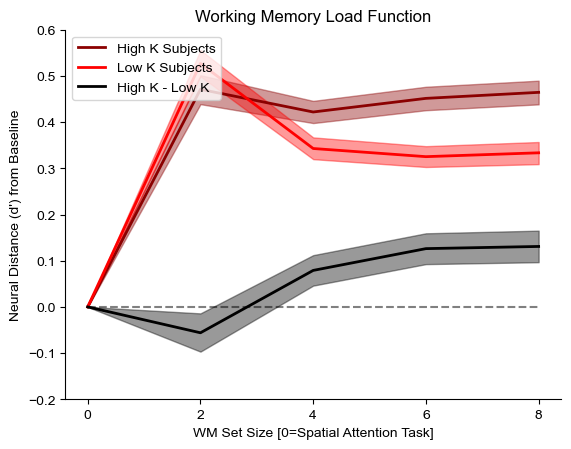

In [24]:
mu_WM_vals = trc["mu_WM"].values

mu_WM_vals = np.concatenate((np.zeros((1, mu_WM_vals.shape[1])), mu_WM_vals), axis=0)  # add 0 for set size 0

plot_param("mu_WM", mu_WM_vals)

mu_WM_sub = trc["sub_vals_WM"].values
plot_param_k_diffs("mu_WM", mu_WM_sub)

# Spatial Attention

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:3: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:4: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 1]


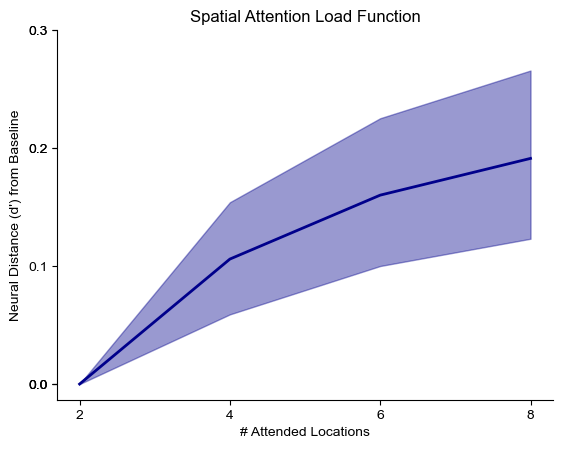

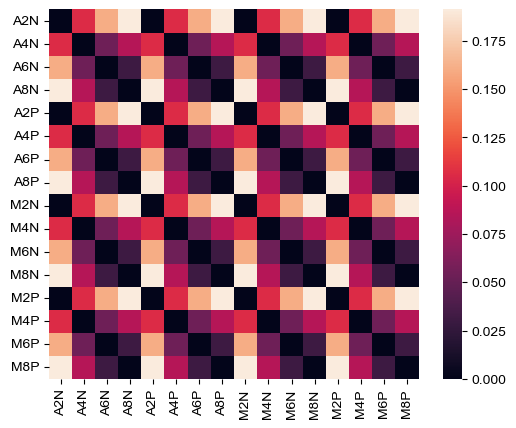

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:43: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  high_K_hdi = az.hdi(sub_vals_high_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:44: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  low_k_hdi = az.hdi(sub_vals_low_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:45: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  diff_hdi = az.hdi(sub_vals_diff.T, hdi_prob=hdi_prob)


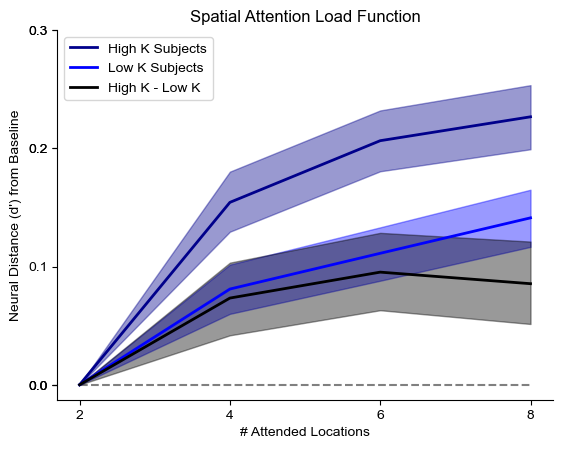

In [25]:
sub_mu_Attn = trc["sub_mu_Attn"].values
sub_scale_Attn = trc["sub_scale_Attn"].values
sub_mu_Attn = sub_mu_Attn * sub_scale_Attn[:, np.newaxis, :]  # scale by subject scale

pop_mu_Attn = trc["pop_mu_Attn"].values
pop_mu_Attn = np.concatenate((np.zeros((1, pop_mu_Attn.shape[1])), pop_mu_Attn), axis=0)  # add 0 for set size 2

plot_param("mu_Attn", pop_mu_Attn)

plot_param_k_diffs("mu_Attn", sub_mu_Attn)

# Spatial Attention

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:3: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:4: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 1]


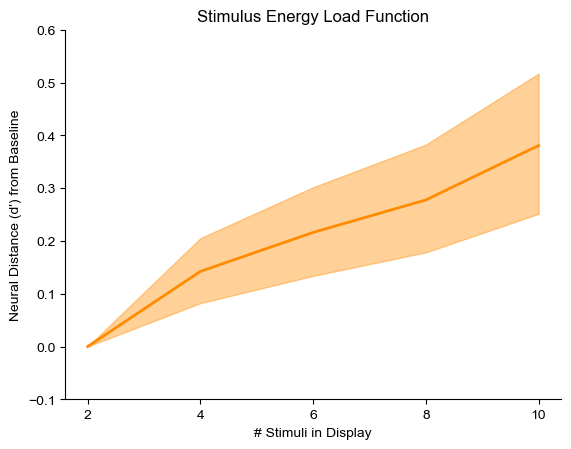

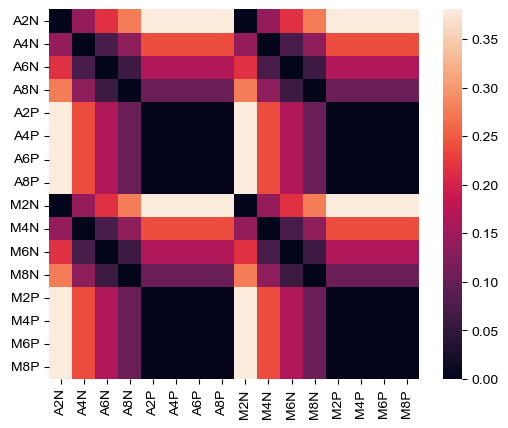

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:43: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  high_K_hdi = az.hdi(sub_vals_high_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:44: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  low_k_hdi = az.hdi(sub_vals_low_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_8582/983111939.py:45: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  diff_hdi = az.hdi(sub_vals_diff.T, hdi_prob=hdi_prob)


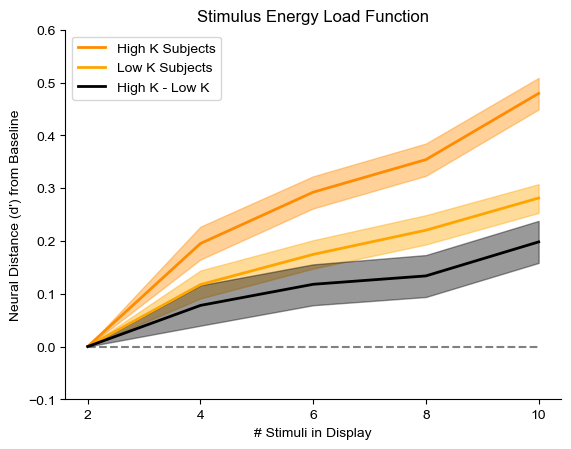

In [27]:
sub_mu_SE = trc["sub_mu_SE"].values
sub_scale_SE = trc["sub_scale_SE"].values
sub_mu_SE = sub_mu_SE * sub_scale_SE[:, np.newaxis, :]  # scale by subject scale

pop_mu_SE = trc["pop_mu_SE"].values
pop_mu_SE = np.concatenate((np.zeros((1, pop_mu_SE.shape[1])), pop_mu_SE), axis=0)  # add 0 for set size 2

plot_param("mu_SE", pop_mu_SE)

plot_param_k_diffs("mu_SE", sub_mu_SE)